# Regresi Total Belanja

Memprediksi `TotalAmount` dari jumlah item, jam transaksi, dan outlet.

## 1. Muat & Siapkan Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('../data/Transactions.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour
df['is_weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int)

X = pd.get_dummies(df[['TotalItem', 'hour', 'is_weekend', 'Outlet']], columns=['Outlet'], drop_first=True)
y = df['TotalAmount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X.shape

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


(53820, 5)

## 2. Latih Model

In [2]:
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

## 3. Evaluasi

In [3]:
print('MAE :', round(mean_absolute_error(y_test, pred), 2))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, pred)), 2))
print('R2  :', round(r2_score(y_test, pred), 3))

MAE : 5642.95
RMSE: 7703.68
R2  : 0.538


## 4. Aktual vs Prediksi

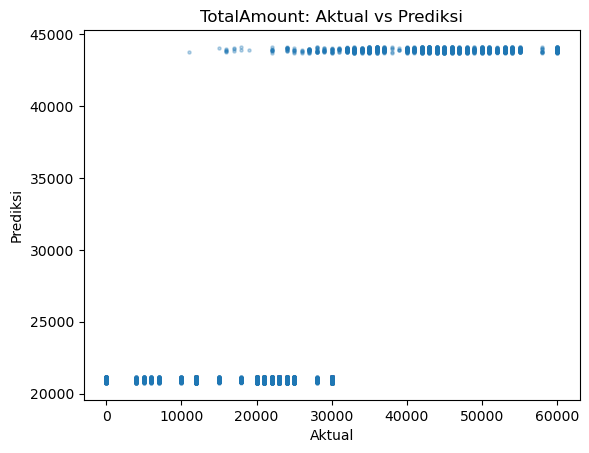

In [4]:
plt.scatter(y_test, pred, s=5, alpha=0.3)
plt.xlabel('Aktual')
plt.ylabel('Prediksi')
plt.title('TotalAmount: Aktual vs Prediksi')
plt.show()